 # **Iris Flower Classification**


**Objective:** Train a machine learning classification model to identify the species of an iris flower (Setosa, Versicolor, or Virginica) from its physical measurements.


**Tech Stack:** Python, scikit-learn, pandas, matplotlib/seaborn, Jupyter Notebook


**Dataset:** Iris dataset (built into scikit-learn): 150 flowers, 4 numeric measurements
(sepal length, sepal width, petal length, petal width), 3 species with 50 flowers each.

**Problem type:** Multi-class classification (predicting a category, not a number).

**Author:** Hanifah Morayo Abdulazeez


In [1]:
#imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets

# Data and modelling
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

# **Load Data**
We will load the datasets using scikit-learn built in datasets.

In [2]:
# Load the iris dataset from sklearn
iris = load_iris(as_frame=True)

#Turn data into dataframe
df = iris.frame

#We add readeable flower names instead of numbers(0, 1, 2)
df['species'] = df['target'].map(lambda x: iris.target_names[x])
df.drop(columns=['target'], inplace=True)
df.columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


# **Exploratory Data Analysis (EDA).**

In [3]:
print("--- 1. Shape ---")
print(df.shape)                       # (150, 5)

print("\n--- 2. Data Types ---")
print(df.dtypes)

print("\n--- 3. Missing Values ---")
print(df.isnull().sum())

print("\n--- 4. Duplicate Rows ---")
print(df.duplicated().sum())          # 1

print("\n--- 5. Class Balance ---")
print(df['species'].value_counts())   # 50 each

print("\n--- 6. Descriptive Statistics ---")
df.describe()

--- 1. Shape ---
(150, 5)

--- 2. Data Types ---
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object
dtype: object

--- 3. Missing Values ---
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

--- 4. Duplicate Rows ---
1

--- 5. Class Balance ---
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

--- 6. Descriptive Statistics ---


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


**Findings from the data check:**
- No missing values.
- 1 duplicate row found. It was kept because it is a real flower measurement, and removing a single row would not change the results.
- The classes are perfectly balanced (50 flowers per species), so accuracy is a fair metric.
- On average, petals are about 3.8 cm long and 1.2 cm wide, and sepals are about 5.8 cm long and 3.1 cm wide.
- Petal length varies the most (standard deviation 1.77). Its median (4.35) is far above its lower quartile (1.6), which hints that the flowers fall into distinct groups. The next charts check this.

**Visualization**

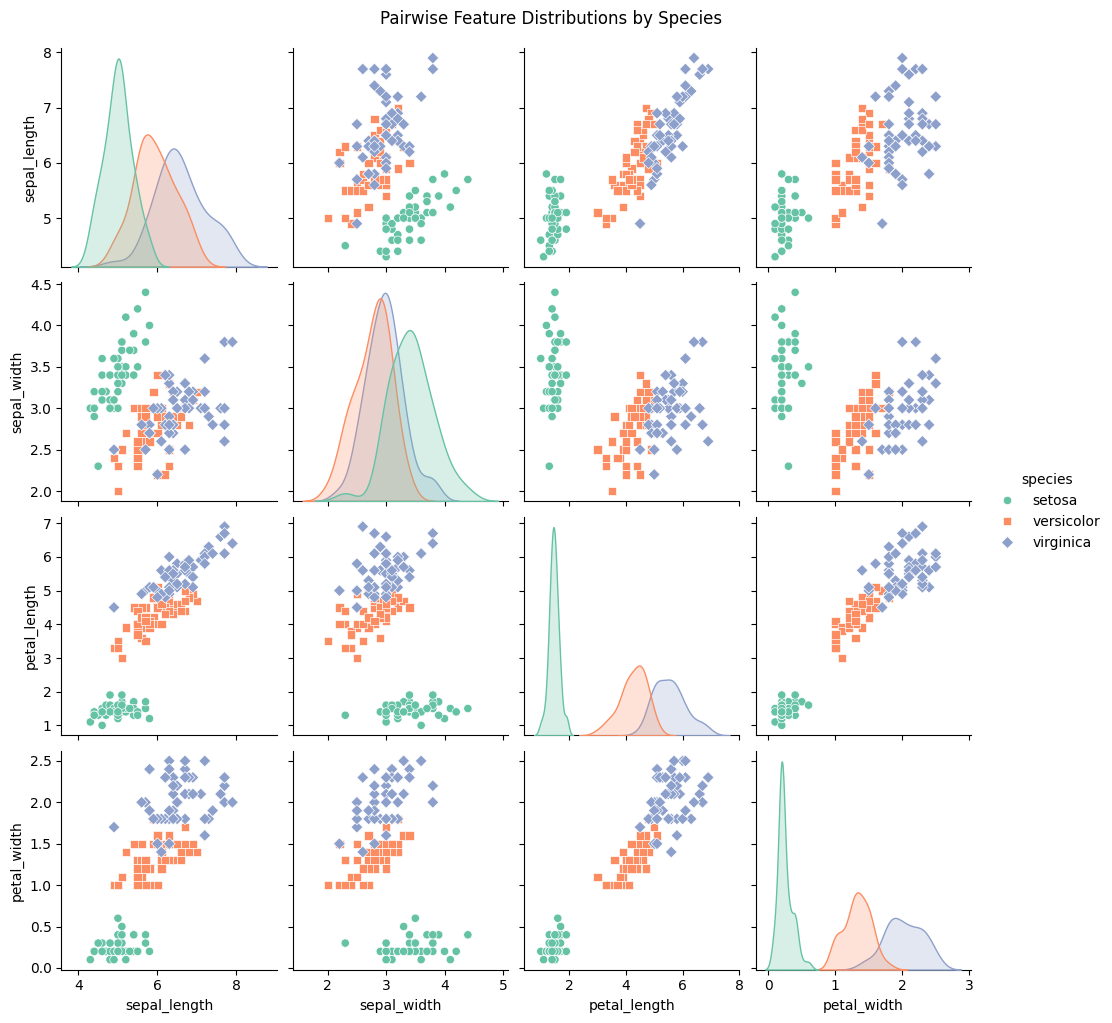

In [4]:
#Pairplot((Feature distributions & relationships by species)
sns.pairplot(df, hue='species', palette='Set2', markers=['o', 's', 'D'])
plt.suptitle("Pairwise Feature Distributions by Species", y=1.02)
plt.show()

**What the pairplot shows:**

The pairplot compares every measurement with every other measurement, with each colour showing a species. The curves on the diagonal show how one measurement is spread out within each species.

- **Setosa** forms its own separate group, away from the other two species in every plot that includes a petal measurement.
- **Versicolor and Virginica** sit next to each other and overlap slightly, so these two will be the hardest for a model to tell apart.
- The plots with **petal length and petal width** separate the three species most clearly. The plots with sepal width show the most mixing.

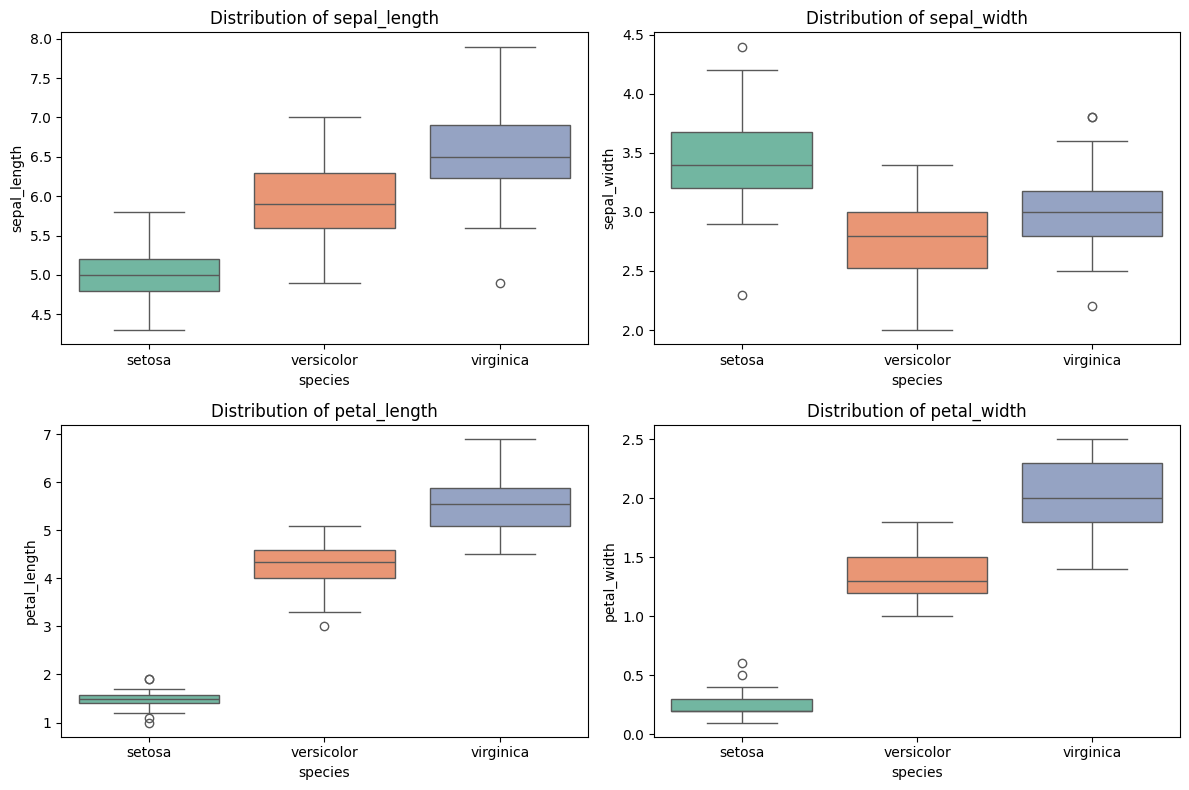

In [5]:
#Box plots for each measurement feature
plt.figure(figsize=(12, 8))
features = df.columns[:-1]

for i, col in enumerate(features):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(x='species', y=col, hue='species', data=df, palette='Set2', legend=False)
    plt.title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

**What the box plots show:**

Each box shows where the middle half of the flowers of a species fall, and the line inside is the median. Boxes that do not overlap mean the feature separates those species well.

- **Petal length and petal width:** The Setosa boxes sit far below the other two and do not overlap them at all. Versicolor and Virginica barely overlap, so these are the best features for telling species apart.
- **Sepal length:** The boxes are in a clear order (Setosa, then Versicolor, then Virginica) but overlap more.
- **Sepal width:** All three species overlap, so this is the weakest feature on its own.
- **Overall:** Petal measurements identify the species better than sepal measurements, and Versicolor vs Virginica remains the hardest pair.

# **Train/Test Split**
- 80% (120 flowers) trains the model, 20% (30 flowers) tests it on data it has never seen.
- `random_state=42` makes the split reproducible.
- `stratify=y` keeps the species balanced in both sets (10 of each species in the test set).


In [6]:
# Separate features (X) and target label (y)
X = df.drop(columns=['species'])
y = df['species']

# Split data: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Print split sizes
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

# Check that each species is equally represented in the test set
print(y_test.value_counts())

Training set size: 120 samples
Testing set size: 30 samples
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


**Result of the split:** The model will learn from 120 flowers and be tested on 30 it has never seen. The test set has exactly 10 flowers of each species, which confirms that `stratify=y` worked. This makes the test fair, because no species is over- or under-represented.

# **Model Training**

We trained two different models so we have something to compare.

- **Logistic Regression** is a simple and fast model. It learns how much each measurement contributes to each species and turns that into a probability. `max_iter=200` gives it enough steps to finish learning.
- **K-Nearest Neighbours (KNN)** classifies a new flower by finding the 5 most similar flowers in the training data (`n_neighbors=5`) and going with the majority species among them.

Both models are trained on the same 120 training flowers and tested on the same 30 test flowers, so the comparison is fair.

In [7]:
# We Initialize two models
log_reg = LogisticRegression(max_iter=200)
knn = KNeighborsClassifier(n_neighbors=5)

# Dictionary to loop through both models easily
models = {
    "Logistic Regression": log_reg,
    "K-Nearest Neighbours (KNN)": knn
}

# Empty dictionary to store each model's test accuracy
results = {}

# Train and evaluate each model
for name, model in models.items():
    # Train model on training data
    model.fit(X_train, y_train)

    # Make predictions on unseen test data
    y_pred = model.predict(X_test)

    # Save this model's accuracy so we can reuse it later
    results[name] = accuracy_score(y_test, y_pred)

    # Calculate evaluation metrics
    print("=" * 55)
    print(f"Model: {name}")
    print("=" * 55)
    print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}\n")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    print("\n")

Model: Logistic Regression
Accuracy Score: 0.9667

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



Model: K-Nearest Neighbours (KNN)
Accuracy Score: 1.0000

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00 

**What the output shows:** On the 30 test flowers, Logistic Regression got 29 right (96.67%) and KNN got all 30 right (100%). Logistic Regression's only mistake was predicting one Versicolor flower as Virginica. Each model's confusion matrix and classification report (precision, recall and F1-score) are printed above and explained in the evaluation section below.

A single test of 30 flowers can be lucky or unlucky, so we check these results with cross-validation further down.

In [8]:
pd.DataFrame(results, index=['Test Accuracy']).T

,Test Accuracy
Logistic Regression,0.966667
K-Nearest Neighbours (KNN),1.000000


**Note on feature scaling:** Features were not scaled because all four are measured in centimetres and sit on similar ranges. On data with mixed units (for example age and income), KNN would need scaling (`StandardScaler`), because it is distance-based and larger-valued features would otherwise dominate.

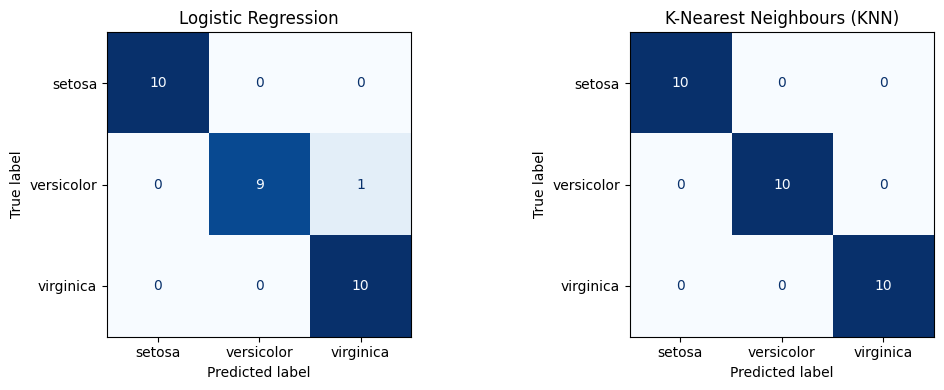

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

Both models classify Setosa perfectly. Logistic Regression's only error is one Versicolor predicted as Virginica.

In [ ]:
# 5-fold stratified cross-validation (with shuffling)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv)
    print(f"{name}: mean = {scores.mean():.4f}, std = {scores.std():.4f}")

Logistic Regression: mean = 0.9667, std = 0.0298
K-Nearest Neighbours (KNN): mean = 0.9667, std = 0.0298


## Model Evaluation and Comparison

### How to read the evaluation metrics
- **Accuracy:** the percentage of test flowers the model classified correctly.
- **Confusion matrix:** a table of actual species (rows) against predicted species (columns). Numbers on the diagonal are correct predictions, and anything off the diagonal is a mistake.
- **Precision:** of all flowers the model predicted as a species, how many were actually that species.
- **Recall:** of all flowers that truly belong to a species, how many the model found.
- **F1-score:** a single score that balances precision and recall.

### Results on the test set (30 flowers)

| Model | Accuracy | Mistakes |
|---|---|---|
| Logistic Regression | 96.67% | 1 out of 30 |
| K-Nearest Neighbours (KNN) | 100% | 0 out of 30 |

**Logistic Regression:** The model classified every Setosa flower correctly. Its only error was predicting one Versicolor flower as Virginica. This lowered Versicolor's recall to 0.90 and Virginica's precision to 0.91.

**KNN:** The model classified all 30 test flowers correctly, with precision, recall and F1-score of 1.00 for all three species.

### Which species were hardest to separate?
Setosa was classified perfectly by both models. The only mistake came from Versicolor and Virginica, which matches the pairplot, where these two species overlap slightly on petal length and petal width. Setosa sits far away from the others, so it is easy to identify.

### Cross-validation check
A single 80/20 split only has 30 test samples, so one flower changes accuracy by about 3.3%. To get a more reliable comparison, I ran 5-fold stratified cross-validation (with shuffling, random_state=42):

| Model | Mean CV Accuracy |
|---|---|
| Logistic Regression | 96.67% (±2.98%) |
| KNN | 96.67% (±2.98%) |

Both models score the same under cross-validation, so the 100% KNN result on the single split was due to a favourable split rather than a real advantage.

### Best-performing model

On the single 80/20 split, KNN scored 100% and Logistic Regression scored 96.67%. However, this gap is one flower out of 30. Under 5-fold cross-validation, both models score 96.67% on average, so there is no meaningful difference between them.

**Recommendation:** Logistic Regression, because it performs just as well, is simpler, trains faster, and is easier to explain to non-technical stakeholders.

**Caveats:** The Iris dataset is small and its classes are well separated, so both models perform very well and the gap between them is small. KNN's perfect score on one split should not be read as a perfect model. On new data, we would expect a few errors, mostly between Versicolor and Virginica.

### Conclusion
Both models classify iris species with about 97% accuracy using petal and sepal measurements. Cross-validation shows no real difference between them. The only confusion is between Versicolor and Virginica, which matches what the charts predicted. The Iris dataset is small and clean, so real-world data would likely give lower scores and need more tuning and validation.

# **Predicting a New Flower**

In [ ]:
# Predict the species of a new, unseen flower
new_flower = pd.DataFrame([[5.1, 3.5, 1.4, 0.2]], columns=X.columns)
print("Predicted species:", log_reg.predict(new_flower)[0])

Predicted species: setosa
